<a href="https://colab.research.google.com/github/CBYERDECODE/image_pixel_manipulator/blob/main/image_pixel_manipulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### # Project: Image Pixel Manipulator
we will build a NumPy-based toolkit to create, manipulate, and analyze synthetic RGB images , we will explore array creation, slicing, cropping, color-channel extraction, brightness adjustments, and memory usage analysis

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Step 1: Create a blank 200x200x3 image and fill regions using `np.full`

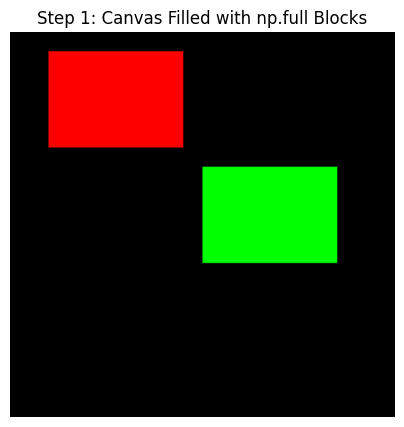

In [2]:
#1. Create a blank black canvas (200x200 pixels, 3 color channels for RGB)
image_step1 = np.zeros((200, 200, 3),dtype=np.uint8)

#2. Define solid color blocks using np.full
red_block = np.full((50, 70, 3), [255, 0, 0], dtype=np.uint8)
green_block = np.full((50, 70, 3), [0, 255, 0], dtype=np.uint8)

#3. Place blocks into the blank canvas using slice assignment
image_step1[10:60, 20:90] = red_block
image_step1[70:120, 100:170] = green_block

#4. Display the result
plt.figure(figsize=(5, 5))
plt.imshow(image_step1)
plt.title("Step 1: Canvas Filled with np.full Blocks")
plt.axis("off")
plt.show()

### Step 2: Draw color blocks and stripes using 3D Slicing

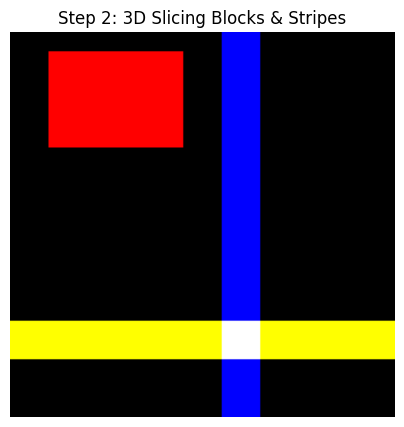

In [3]:
# 1. Create a new blank canvas
image_step2 = np.zeros((200, 200, 3), dtype=np.uint8)

# 2. Draw a red block directly using channel indexing (channel 0 is Red)
image_step2[10:60, 20:90, 0] = 255

# 3. Draw a blue vertical stripe (channel 2 is Blue)
image_step2[:, 110:130, 2] = 255

# 4. Draw a yellow horizontal stripe (Yellow = Red + Green)
image_step2[150:170, :, 0] = 255
image_step2[150:170, :, 1] = 255

# 5. Display the result
plt.figure(figsize=(5, 5))
plt.imshow(image_step2)
plt.title("Step 2: 3D Slicing Blocks & Stripes")
plt.axis("off")
plt.show()

### Step 3: Crop, Flip, and Extract R/G/B Channels

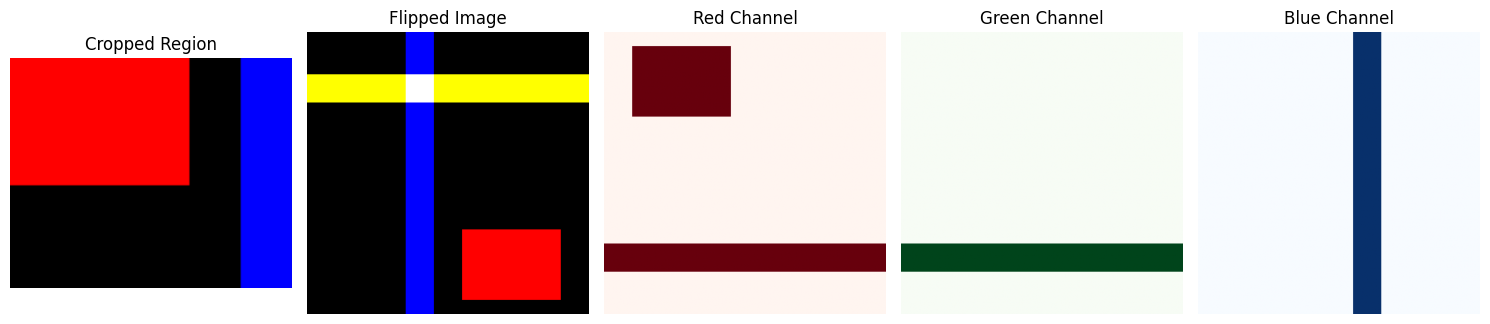

In [4]:
# 1. Crop a region of interest (ROI)
cropped_region = image_step2[10:100, 20:130].copy()

# 2. Flip the image vertically and horizontally using negative steps
flipped_image = image_step2[::-1, ::-1, :]

# 3. Extract individual color channels
r_channel = image_step2[:, :, 0]
g_channel = image_step2[:, :, 1]
b_channel = image_step2[:, :, 2]

# 4. Visualize the results
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))

axes[0].imshow(cropped_region)
axes[0].set_title("Cropped Region")
axes[0].axis("off")

axes[1].imshow(flipped_image)
axes[1].set_title("Flipped Image")
axes[1].axis("off")

axes[2].imshow(r_channel, cmap='Reds')
axes[2].set_title("Red Channel")
axes[2].axis("off")

axes[3].imshow(g_channel, cmap='Greens')
axes[3].set_title("Green Channel")
axes[3].axis("off")

axes[4].imshow(b_channel, cmap='Blues')
axes[4].set_title("Blue Channel")
axes[4].axis("off")

plt.tight_layout()
plt.show()

### Step 4: Brighten/Darken using float32 Casting and Apply Bright Pixels Mask

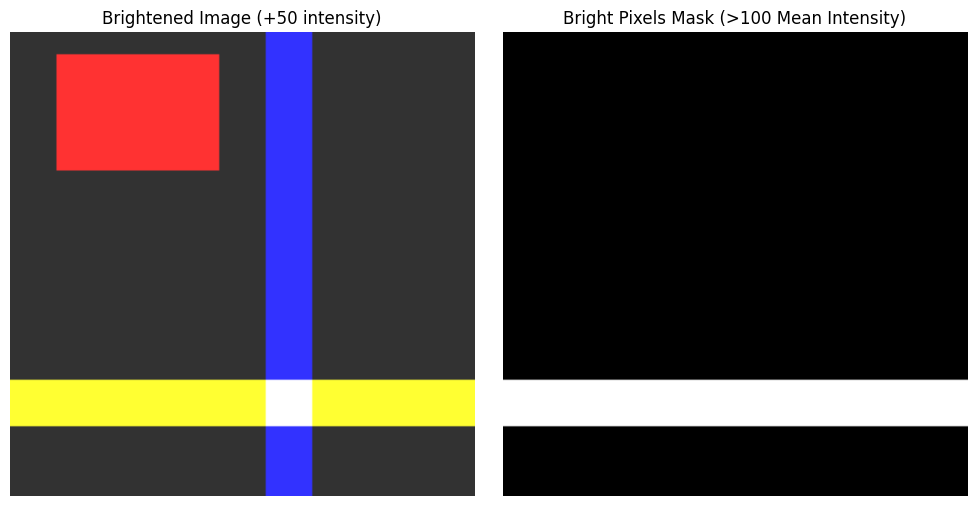

In [5]:
# 1. Cast the uint8 image to float32 to prevent overflow wrapping during arithmetic operations
float_img = image_step2.astype(np.float32)

# 2. Brighten the image by adding intensity, then clip boundaries to [0, 255]
brightened_float = np.clip(float_img + 50.0, 0, 255)
brightened_img = brightened_float.astype(np.uint8)

# 3. Calculate a binary mask representing bright pixels where average RGB channel intensity is > 100
bright_mask = np.mean(image_step2, axis=2) > 100

# 4. Visualize brightened image alongside the binary mask
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(brightened_img)
axes[0].set_title("Brightened Image (+50 intensity)")
axes[0].axis("off")

axes[1].imshow(bright_mask, cmap='gray')
axes[1].set_title("Bright Pixels Mask (>100 Mean Intensity)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Step 5: Compare memory usage of uint8 vs float64

uint8 Image Memory Usage: 120000 bytes
float64 Image Memory Usage: 960000 bytes
float64 uses 8.0x more memory than uint8!



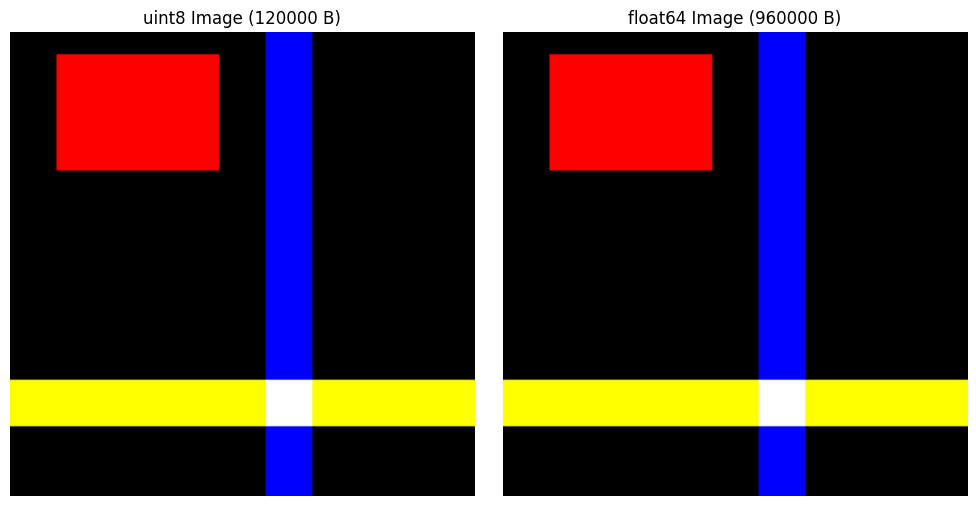

In [6]:
# 1. Create a representation of our image in uint8 and float64 representations
image_uint8 = image_step2.copy()
image_float64 = image_step2.astype(np.float64)

# 2. Get byte sizes using .nbytes
uint8_bytes = image_uint8.nbytes
float64_bytes = image_float64.nbytes

print(f"uint8 Image Memory Usage: {uint8_bytes} bytes")
print(f"float64 Image Memory Usage: {float64_bytes} bytes")
print(f"float64 uses {float64_bytes / uint8_bytes:.1f}x more memory than uint8!\n")

# 3. Render both side-by-side using plt.imshow
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image_uint8)
axes[0].set_title(f"uint8 Image ({uint8_bytes} B)")
axes[0].axis("off")

# float64 images must be normalized to [0.0, 1.0] for plt.imshow to render properly
axes[1].imshow(image_float64 / 255.0)
axes[1].set_title(f"float64 Image ({float64_bytes} B)")
axes[1].axis("off")

plt.tight_layout()
plt.show()